In [1]:
%load_ext lab_black

import pandas as pd
import numpy as np
import polars as pl
from tqdm import tqdm
import os
import gc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings

warnings.filterwarnings("ignore")

pd.set_option("max_rows", 500)

%matplotlib inline

In [2]:
catalog.exists("sample_submission")

True

In [3]:
catalog.exists("df_train"), catalog.exists("df_test")

(True, True)

In [4]:
%%time

df_train = catalog.load("df_train")
df_test = catalog.load("df_test")

df_train.name = "df_train"
df_test.name = "df_test"

def make_date_stats(df):
    df['date'] = pd.to_datetime((df["ts"] + 1000 * 60 * 60 * 2) * 1e6)
    df['date_day'] = df['date'].dt.to_period("d")
    df['n_day'] = df['date'].dt.day
    df['n_week'] = df['date'].dt.isocalendar().week
    df['dayofweek'] = df['date'].dt.dayofweek
    df['hour'] = df['date'].dt.hour
    return df

df_train = make_date_stats(df_train)
df_test = make_date_stats(df_test)

# df_train = pl.from_pandas(df_train)
# df_test = pl.from_pandas(df_test)

[12/11/22 00:55:55] INFO     Loading data from 'df_train' (ParquetDataSet)...                   ]8;id=330047;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=140627;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

[12/11/22 00:56:12] INFO     Loading data from 'df_test' (ParquetDataSet)...                    ]8;id=918259;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=903900;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

CPU times: user 1min 53s, sys: 26.3 s, total: 2min 20s
Wall time: 1min 55s


In [5]:
df_train

,user,aid,ts,type,n_session,date,date_day,n_day,n_week,dayofweek,hour
0,0,1517085,1659304800025,clicks,0,2022-08-01 00:00:00.024999936,2022-08-01,1,31,0,0
1,0,1563459,1659304904511,clicks,0,2022-08-01 00:01:44.511000064,2022-08-01,1,31,0,0
2,0,1309446,1659367439426,clicks,1,2022-08-01 17:23:59.425999872,2022-08-01,1,31,0,17
3,0,16246,1659367719997,clicks,1,2022-08-01 17:28:39.996999936,2022-08-01,1,31,0,17
4,0,1781822,1659367871344,clicks,1,2022-08-01 17:31:11.344000000,2022-08-01,1,31,0,17
...,...,...,...,...,...,...,...,...,...,...,...
216716091,12899776,1737908,1661723987073,clicks,0,2022-08-28 23:59:47.072999936,2022-08-28,28,34,6,23
216716092,12899777,384045,1661723976974,clicks,0,2022-08-28 23:59:36.974000128,2022-08-28,28,34,6,23
216716093,12899777,384045,1661723986800,clicks,0,2022-08-28 23:59:46.800000000,2022-08-28,28,34,6,23
216716094,12899778,561560,1661723983611,clicks,0,2022-08-28 23:59:43.611000064,2022-08-28,28,34,6,23


In [6]:
df_test

,user,aid,ts,type,n_session,date,date_day,n_day,n_week,dayofweek,hour
0,12899779,59625,1661724000278,clicks,0,2022-08-29 00:00:00.278000128,2022-08-29,29,35,0,0
1,12899780,1142000,1661724000378,clicks,0,2022-08-29 00:00:00.377999872,2022-08-29,29,35,0,0
2,12899780,582732,1661724058352,clicks,0,2022-08-29 00:00:58.352000000,2022-08-29,29,35,0,0
3,12899780,973453,1661724109199,clicks,0,2022-08-29 00:01:49.199000064,2022-08-29,29,35,0,0
4,12899780,736515,1661724136868,clicks,0,2022-08-29 00:02:16.868000000,2022-08-29,29,35,0,0
...,...,...,...,...,...,...,...,...,...,...,...
6928118,14571577,1141710,1662328774770,clicks,0,2022-09-04 23:59:34.769999872,2022-09-04,4,35,6,23
6928119,14571578,519105,1662328775009,clicks,0,2022-09-04 23:59:35.008999936,2022-09-04,4,35,6,23
6928120,14571579,739876,1662328775605,clicks,0,2022-09-04 23:59:35.604999936,2022-09-04,4,35,6,23
6928121,14571580,202353,1662328781067,clicks,0,2022-09-04 23:59:41.067000064,2022-09-04,4,35,6,23


In [7]:
df_train["type"].value_counts()

clicks    194720954
carts      16896191
orders      5098951
Name: type, dtype: int64

In [8]:
df_train["date"].min(), df_train["date"].max()

(Timestamp('2022-08-01 00:00:00.024999936'), Timestamp('2022-08-28 23:59:59.984000'))

In [9]:
df_test["date"].min(), df_test["date"].max()

(Timestamp('2022-08-29 00:00:00.278000128'), Timestamp('2022-09-04 23:59:51.563000064'))

In [10]:
%%time

df_train.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 16.7 s, sys: 8.18 s, total: 24.9 s
Wall time: 24.4 s


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 2335991 
 
 
 clicks 
 27514030 
 
 
 orders 
 734694 
 
 
 1 
 carts 
 2442264 
 
 
 clicks 
 27227839 
 
 
 orders 
 788182 
 
 
 2 
 carts 
 2360846 
 
 
 clicks 
 26985981 
 
 
 orders 
 704832 
 
 
 3 
 carts 
 2204026 
 
 
 clicks 
 25538575 
 
 
 orders 
 645485 
 
 
 4 
 carts 
 2274907 
 
 
 clicks 
 26183716 
 
 
 orders 
 659433 
 
 
 5 
 carts 
 2325947 
 
 
 clicks 
 27280343 
 
 
 orders 
 663990 
 
 
 6 
 carts 
 2952210 
 
 
 clicks 
 33990470 
 
 
 orders 
 902335

In [11]:
%%time

df_test.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 578 ms, sys: 125 ms, total: 703 ms
Wall time: 701 ms


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 87577 
 
 
 clicks 
 924175 
 
 
 orders 
 13547 
 
 
 1 
 carts 
 84719 
 
 
 clicks 
 960098 
 
 
 orders 
 10849 
 
 
 2 
 carts 
 87353 
 
 
 clicks 
 949862 
 
 
 orders 
 10755 
 
 
 3 
 carts 
 77150 
 
 
 clicks 
 838805 
 
 
 orders 
 8738 
 
 
 4 
 carts 
 68115 
 
 
 clicks 
 758053 
 
 
 orders 
 7108 
 
 
 5 
 carts 
 73291 
 
 
 clicks 
 850542 
 
 
 orders 
 6649 
 
 
 6 
 carts 
 91806 
 
 
 clicks 
 1011097 
 
 
 orders 
 7834

In [12]:
df_train_n_session = (df_train.groupby("user")[["n_session"]].max() + 1).reset_index()
df_test_n_session = (df_test.groupby("user")[["n_session"]].max() + 1).reset_index()

In [13]:
df_train_n_session["n_session"].value_counts()

1      4861373
2      3294399
3      1564799
4       886517
5       558291
6       378977
7       268371
8       198763
9       151469
10      118186
11       94641
12       76397
13       63582
14       52273
15       43830
16       37308
17       31713
18       27244
19       23499
20       20178
21       17605
22       15219
23       13591
24       11891
25       10531
26        9110
27        8054
28        7111
29        6425
30        5533
31        4956
32        4396
33        3893
34        3448
35        3134
36        2684
37        2382
38        2150
39        1893
40        1640
41        1469
42        1372
43        1132
44        1042
45         925
46         754
47         690
48         628
49         538
50         451
51         450
52         352
53         341
54         304
55         238
56         231
58         197
57         182
59         145
60         127
61         102
62          87
63          78
64          73
65          65
67          54
66          41
68          31
69          22
74          22
72          22
70          21
71          18
73          18
75          15
79          12
77          11
76          11
78           6
81           4
84           4
87           4
86           4
82           3
90           3
80           3
93           3
103          2
88           2
85           2
111          1
98           1
92           1
99           1
107          1
91           1
106          1
89           1
127          1
83           1
96           1
100          1
Name: n_session, dtype: int64

In [14]:
df_test_n_session["n_session"].value_counts()

1     1486287
2      141422
3       29506
4        8839
5        3156
6        1308
7         583
8         310
9         167
10        100
11         60
12         34
13         14
15          6
14          5
16          2
17          2
18          1
19          1
Name: n_session, dtype: int64

In [15]:
def plot_n_interactions_per_dayofweek(df):
    try:
        df_name = df.name
    except AttributeError:
        df_name = None

    title = "n_interactions per dayofweek"
    if df_name is not None:
        title += f" in {df_name}"

    plt.figure(figsize=(12, 7))
    plt.title(title)
    plt.xlabel("dayofweek")
    plt.ylabel("n_interactions")

    dict_type_inter_offset = dict()
    dict_type_inter_offset["clicks"] = -0.2
    dict_type_inter_offset["carts"] = 0.0
    dict_type_inter_offset["orders"] = 0.2

    dict_type_inter_color = dict()
    dict_type_inter_color["clicks"] = "b"
    dict_type_inter_color["carts"] = "g"
    dict_type_inter_color["orders"] = "r"

    for (dayofweek, type_inter), df_cur in df.groupby(["dayofweek", "type"]):
        ys = df_cur["ts"].count()
        plt.bar(
            dayofweek + dict_type_inter_offset[type_inter],
            ys,
            width=0.2,
            color=dict_type_inter_color[type_inter],
            align="center",
            # label=feature,
            # marker=",",
            # linestyle="dashed",
            alpha=0.6,
        )

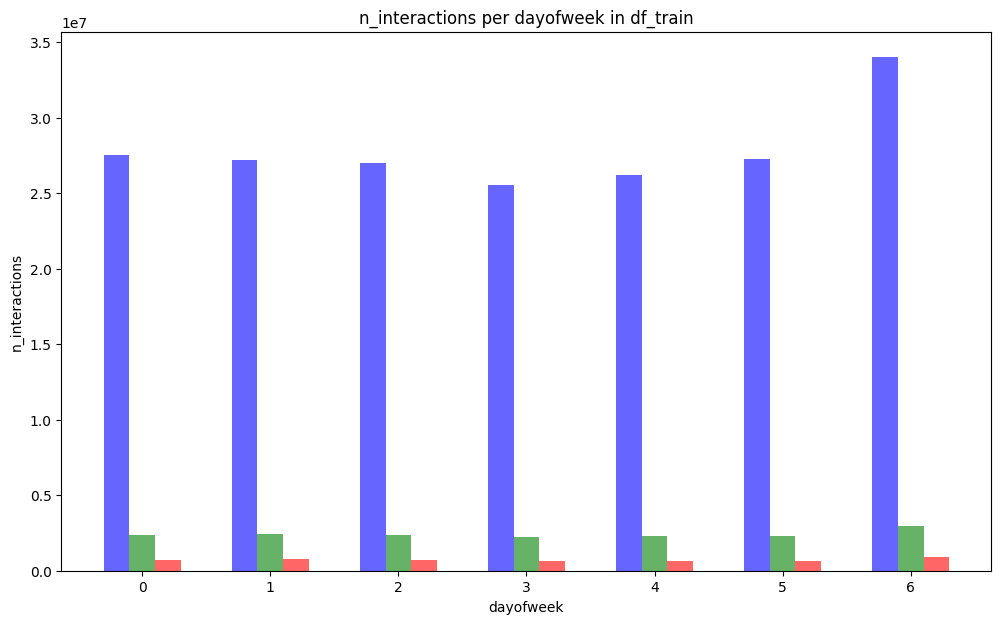

In [16]:
plot_n_interactions_per_dayofweek(df_train)

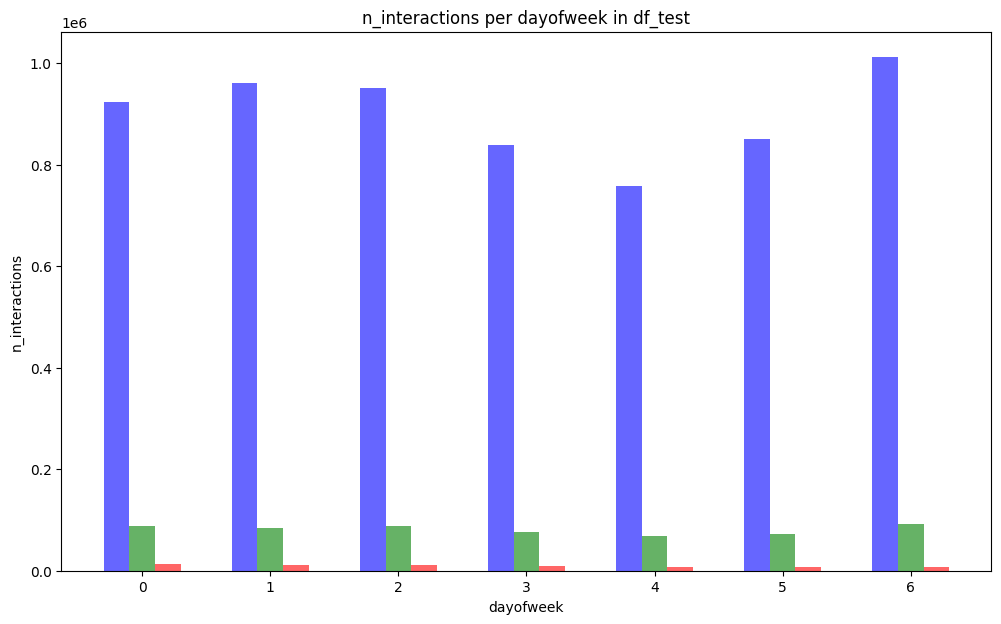

In [17]:
plot_n_interactions_per_dayofweek(df_test)

In [108]:
def plot_user_activity(user, df):
    dict_type_inter_color = dict()
    dict_type_inter_color["clicks"] = "b"
    dict_type_inter_color["carts"] = "g"
    dict_type_inter_color["orders"] = "r"

    offset = 0.5
    df_cur = df[df["user"] == user]
    df_cur["date_day"] = df_cur["date_day"].astype(str)

    if df.name == "df_train":
        x = pd.date_range("2022-08-01", "2022-08-28")
    elif df.name == "df_test":
        x = pd.date_range("2022-08-29", "2022-09-04")
    x = [str(d).split(" ")[0] for d in x]
    map_dates = {x[i]: i for i in range(len(x))}
    points_sundays = [point for point in range(len(x)) if (point + 1) % 7 == 0]

    plt.figure(figsize=(12, 7))
    plt.xticks(range(len(x)), x, rotation=90)
    plt.yticks(range(25))

    for point in range(25):
        plt.axhline(y=point, color="gray", linestyle="-", alpha=0.1)
    for point in range(len(x)):
        plt.axvline(x=point + offset, color="gray", linestyle="-", alpha=0.1)
        plt.axvline(x=point - offset, color="gray", linestyle="-", alpha=0.1)
    for point in points_sundays:
        plt.axvline(x=point + offset, color="r", linestyle="-", alpha=0.3)
        plt.axvline(x=point - offset, color="r", linestyle="-", alpha=0.3)
        plt.axvline(x=point + offset - 1, color="r", linestyle="-", alpha=0.3)
        plt.axvline(x=point - offset - 1, color="r", linestyle="-", alpha=0.3)

    for action, df_cur_action in df_cur.groupby("type"):
        xx = np.random.uniform(-0.15, 0.15, len(df_cur_action))
        yy = np.random.uniform(-0.5, 0.5, len(df_cur_action))
        plt.scatter(
            df_cur_action["date_day"].map(map_dates) + xx,
            df_cur_action["hour"] + yy,
            c=dict_type_inter_color[action],
            s=10,
        )

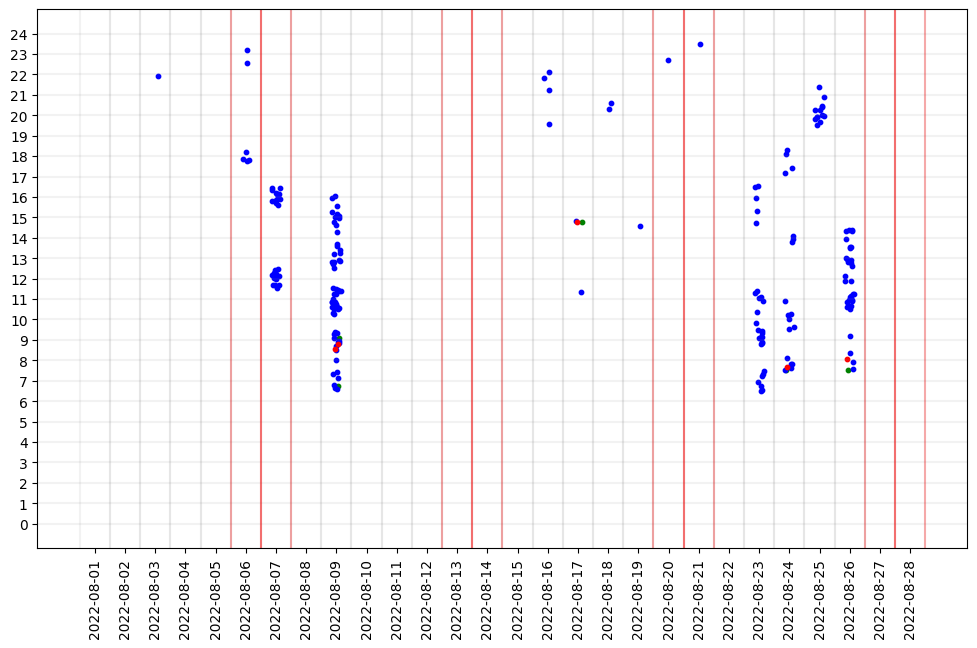

In [109]:
plot_user_activity(user=2932269, df=df_train)

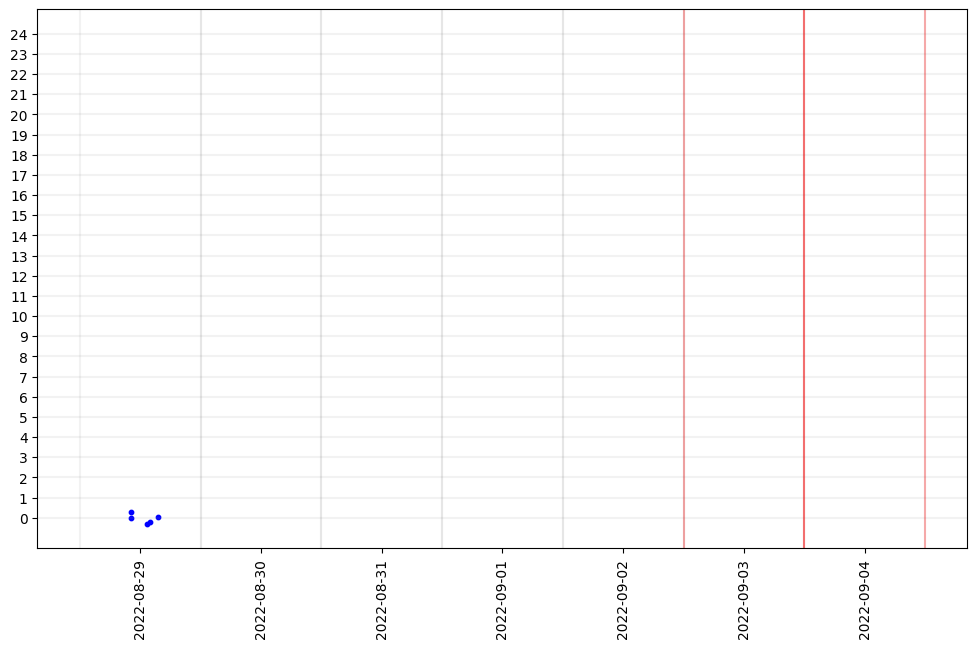

In [110]:
plot_user_activity(user=12899780, df=df_test)